# Lab 2: Deep Learning Mini-Project: Image Quality Assessment

Authors: Alexandre Bruckert, Nantes Université

Date: 2026/2027

Over the next two lab sessions (6 hours), you will transition from learning basic PyTorch syntax to designing, optimizing, and evaluating neural networks for a real-world task.

## The task: Image Quality Assessment (IQA)

Instead of classifying what is in an image, you will predict how good it looks.
You are tackling an Image Quality Assessment (IQA) task. Your model will analyze an image and predict its Mean Opinion Score (MOS), which is a continuous value usually ranging from 1.0 (terrible quality) to 5.0 (excellent quality), representing the average human perception of the image's visual appeal, sharpness, and lack of distortions.

Because the target is a continuous number, this is a **regression** problem.

## The Dataset: KonIQ-10k
For this challenge, you will be working with the **KonIQ-10k** dataset, a major benchmark in the field of Image Quality Assessment. It consists of 10,073 images carefully sampled from a massive public multimedia database. Unlike older academic datasets where pristine images were artificially corrupted with math-generated noise, KonIQ-10k features **"in-the-wild" authentic distortions**. This means the images suffer from real-world, everyday issues: poor lighting, shaky hands (motion blur), cheap camera sensors, and aggressive JPEG compression. The ground truth MOS labels (ranging from 1.0 to 5.0) were collected through a massive crowdsourcing effort involving over 1.2 million human ratings.

The KonIQ-10k dataset is available at: https://database.mmsp-kn.de/koniq-10k-database.html
You should use the lower resolution images ($512 \times 384$) for this work.

## Evaluation

You are tasked with building the best model possible for this task. You will be evaluated based on a **heavily documented** notebook that contains your code, results, and analysis. The notebook should be structured to clearly present your approach, experiments, and findings.

Your notebook must contain the following distinct sections, representing "milestones" in the project:

- Milestone 1: The CNN Baseline: Design and train a Convolutional Neural Network (CNN) using MSELoss.

- Milestone 2: The RNN Experiment: Treat the image as a sequence of pixel rows! Design a Recurrent Neural Network (LSTM or GRU) to predict the MOS. Compare its performance to the CNN.

- Milestone 3: The Transfer Learning Approach: Use a pre-trained model (e.g., ResNet, EfficientNet) as a feature extractor. Fine-tune it for the IQA task and compare its performance to your previous models.

- Milestone 4: The Ultimate Model: Combine Early Stopping, Schedulers, Regularization, and your best architecture to build your final model.

Similarly to the grid in Lab 1, the concepts explored in each milestone will be part of the program of the final exam!

## 1. Setup

Here below, you will find the necessary imports and a custom Dataset class to load the KonIQ-10k dataset. You will need to download the dataset and place it in a folder named `iqa_data` with the following structure:
```
iqa_data/
├── images/
├── train_labels.csv
```

In [3]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset, random_split
from torchvision import transforms
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import os

# Device configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

def set_seed(seed=42):
    torch.manual_seed(seed)
    np.random.seed(seed)
set_seed(42)

# ====================================================================
# 1. CUSTOM DATASET CLASS (Provided)
# ====================================================================
# In real-world projects, data doesn't come neatly packaged in PyTorch.
# You have a folder of images and a CSV file with labels.
# We build a custom Dataset class to handle this.

class IQADataset(Dataset):
    def __init__(self, csv_file, img_dir, transform=None):
        """
        Args:
            csv_file (string): Path to the csv file with annotations (columns: image_id, mos).
            img_dir (string): Directory with all the images.
            transform (callable, optional): Optional transform to be applied on a sample.
        """
        # Load the CSV file
        self.labels_df = pd.read_csv(csv_file)
        self.img_dir = img_dir
        self.transform = transform

    def __len__(self):
        return len(self.labels_df)

    def __getitem__(self, idx):
        # Get image name and target MOS
        img_name = str(self.labels_df.iloc[idx]['image_name'])
        mos = float(self.labels_df.iloc[idx]['MOS'])

        # Load image from disk
        img_path = os.path.join(self.img_dir, img_name)
        image = Image.open(img_path).convert('RGB')

        # Apply transformations (e.g., resizing, converting to tensor)
        if self.transform:
            image = self.transform(image)

        # Return the image and the MOS (as a float32 tensor for regression)
        return image, torch.tensor(mos, dtype=torch.float32)

# ====================================================================
# DATA LOADING EXAMPLE
# ====================================================================
# Resize all images to 128x128 to keep training relatively fast
base_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

# Assuming you have downloaded the dataset into a folder named 'iqa_data'
# containing 'images/' folder and 'train_labels.csv'
#
dataset = IQADataset(csv_file='iqa_data/train_labels.csv',
                      img_dir='iqa_data/images',
                      transform=base_transform)

sample, label = dataset[0]
print(f"Sample {0}: {sample}")
print(f"Label {0}: {label}")

print("Dataset class ready! Your turn to instantiate it and create DataLoaders.")

Using device: cpu
Sample 0: tensor([[[ 0.2706, -0.3647, -0.4039,  ..., -0.6157, -0.6471, -0.6078],
         [-0.3490, -0.5216, -0.2784,  ..., -0.8667, -0.8588, -0.8824],
         [-0.8980, -0.8824, -0.7725,  ..., -0.9216, -0.8431, -0.7647],
         ...,
         [-0.4980, -0.5686, -0.2392,  ..., -0.7725, -0.9137, -0.8824],
         [-0.5451, -0.5529, -0.4980,  ..., -0.7804, -0.9294, -0.9137],
         [-0.3569, -0.3647, -0.4980,  ..., -0.8353, -0.9294, -0.9294]],

        [[ 0.3176, -0.2863, -0.3412,  ..., -0.3333, -0.4353, -0.3882],
         [-0.1922, -0.3647, -0.1686,  ..., -0.7725, -0.7804, -0.8353],
         [-0.7882, -0.7804, -0.6549,  ..., -0.9373, -0.8196, -0.7176],
         ...,
         [-0.3176, -0.4667, -0.1294,  ..., -0.6784, -0.8824, -0.8667],
         [-0.3490, -0.3882, -0.3176,  ..., -0.7020, -0.9059, -0.8980],
         [-0.1765, -0.2078, -0.3098,  ..., -0.7882, -0.9059, -0.9137]],

        [[ 0.3804, -0.2471, -0.2784,  ..., -0.0510, -0.3255, -0.3490],
         [-0.2157

# Milestone 1


Train : 8058 | Val : 2015

--- 3. Creating DataLoaders ---

--- 4. Batch Visualization ---


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..0.5764706].


Shape of an image batch : torch.Size([64, 3, 128, 128])


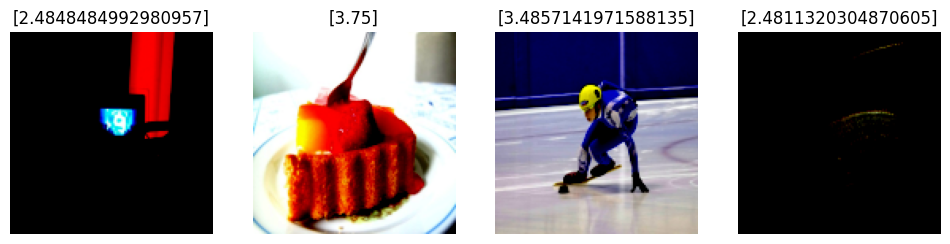

In [4]:
generator = torch.Generator().manual_seed(123)

# TODO : Divide raw_dataset into train_dataset (80%) and val_dataset (20%)
# train_dataset, val_dataset = ...
train_size = int(0.8 * len(dataset))
val_size = int(len(dataset) - train_size)

train_dataset, val_dataset = random_split(dataset, [train_size, val_size])

print(f"Train : {len(train_dataset)} | Val : {len(val_dataset)}")

print("\n--- 3. Creating DataLoaders ---")
# The batch_size is a hyperparameter that controls the size of the batches (i.e. how many images are fed to the model at each iteration).
batch_size = 64

# TODO : Create the corresponding DataLoaders.
# IMPORTANT : it is particularly important to shuffle (arg. shuffle=True) the train_loader
# in order to avoid having the model memorizing the order of the images.
# This is not necessary for the validation and test loaders.
# train_loader = ...
# val_loader = ...
# test_loader = ...
train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False
)



print("\n--- 4. Batch Visualization ---")

images, labels = next(iter(train_loader))

print(f"Shape of an image batch : {images.shape}")



fig, axes = plt.subplots(1, 4, figsize=(12, 3))
for i in range(4):
    
    img = images[i].squeeze().permute(1,2,0)
    axes[i].set_title([labels[i].item()])

    axes[i].imshow(img)
    axes[i].axis('off')
plt.show()


In [5]:

import torch.nn as nn


class CNN(nn.Module):
    def __init__(self, input_channels=3, image_size=128,conv_channels=[32, 64, 128], hidden_sizes=[256, 128], dropout_rate=0.0, score_min=1.0, score_max=5.0,
    ):
        """
        CNN for image quality regression.

        :param input_channels: Number of image channels (3 for RGB, 1 for grayscale).
        :param image_size: Spatial size of the square input image, e.g. 128.
        :param conv_channels: Number of filters in each convolutional block.
        :param hidden_sizes: Number of neurons in each fully connected hidden layer.
        :param dropout_rate: Dropout probability.
        :param score_min: Minimum possible rating.
        :param score_max: Maximum possible rating.
        """
        super(CNN, self).__init__()

        self.score_min = score_min
        self.score_max = score_max

        # ----- Convolutional feature extractor -----
        conv_layers = []
        in_channels = input_channels

        for out_channels in conv_channels:
            conv_layers.extend([
                nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
                nn.BatchNorm2d(out_channels),
                nn.ReLU(),
                nn.MaxPool2d(kernel_size=2, stride=2),
                nn.Dropout2d(dropout_rate),
            ])
            in_channels = out_channels

        self.features = nn.Sequential(*conv_layers)

        # ----- Compute flattened feature size dynamically -----
        # With 3 MaxPool layers: 128 -> 64 -> 32 -> 16
        feature_map_size = image_size // (2 ** len(conv_channels))
        flattened_size = conv_channels[-1] * feature_map_size * feature_map_size

        # ----- Fully connected regression head -----
        fc_layers = []
        in_features = flattened_size

        for hidden_size in hidden_sizes:
            fc_layers.extend([
                nn.Linear(in_features, hidden_size),
                nn.BatchNorm1d(hidden_size),
                nn.ReLU(),
                nn.Dropout(dropout_rate),
            ])
            in_features = hidden_size

        # Final regression layer: exactly one output, no activation
        fc_layers.append(nn.Linear(in_features, 1))

        self.classifier = nn.Sequential(*fc_layers)

    def forward(self, x):
        """
        :param x: Tensor of shape [batch_size, channels, height, width]
        :return: Tensor of shape [batch_size] containing scores in [1.0, 5.0]
        """
        x = self.features(x)
        x = torch.flatten(x, 1)
        x = self.classifier(x)

        # Shape [batch_size, 1] -> [batch_size]
        x = x.squeeze(1)

        # Optional: constrain prediction to the valid rating range
        x = self.score_min + (self.score_max - self.score_min) * torch.sigmoid(x)

        return x


### Model Training

In [6]:
import torch.optim as optim

# Good practice: Code should be agnostic to the device (allows for CPU, CUDA, or MPS usage).
# We will use the device variable to move our model and data to the appropriate device.
device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
print(f"Device : {device}")

def train_epoch(model, dataloader, criterion, optimizer, device):
    """
    Trains a PyTorch model for one complete epoch using provided data, loss
    function, and optimizer. Keeps track of accumulated loss and accuracy
    metrics across the epoch and returns these values.

    :param model: (torch.nn.Module) PyTorch model to be trained.
    :param dataloader: (torch.utils.data.Dataloader) Iterable DataLoader object providing batches of
                       input data and corresponding labels.
    :param criterion: (torch.nn.Module) Loss function used for training the model.
    :param optimizer: (torch.optim.Optimizer) The optimization algorithm to update model parameters.
    :param device: (torch.device) The device on which computation is performed (e.g., 'cpu'
                   or 'cuda').

    :return: (tuple[float,float]) Tuple containing the normalized loss and accuracy for the
             epoch.
    """
    model.train() # Set model to training mode (enables Dropout, etc.)
    running_loss = 0.0
    running_abs_error = 0.0
    total = 0

    for inputs, labels in dataloader:
        # Move data to the same device as the model (CPU or GPU)
        inputs, labels = inputs.to(device), labels.to(device)

        # TODO: Implement the 5 golden steps of PyTorch training
        # 1. Zero the gradients
        # optimizer...
        optimizer.zero_grad()
        
        # 2. Forward pass
        # outputs = ...
        outputs = model(inputs)
        
        # 3. Compute the loss
        # loss = ...
        loss = criterion(outputs, labels)
        
        # 4. Backward pass
        # loss...
        loss.backward()
        
        # 5. Optimizer step
        # optimizer...
        optimizer.step()
        
        # --- Metrics Calculation ---
        # TODO: Get the predicted class (the index of the highest probability)
        # preds = ...
        batch_size = labels.size(0)
        # Update statistics
        running_loss += loss.item() * batch_size
        running_abs_error += torch.abs(outputs - labels).sum().item()
        total += batch_size

    epoch_loss = running_loss / total
    epoch_mae = running_abs_error / total
    return epoch_loss, epoch_mae

def validation(model, dataloader, criterion, device):
    """
    Evaluates a given model using a provided dataloader and criterion, and computes
    the average loss and accuracy over the evaluation dataset.

    :param model: (torch.nn.Module) Neural network model to be evaluated.
    :param dataloader: (torch.utils.data.Dataloader) Iterable over the dataset for evaluation, providing input
        data and associated labels in mini-batches.
    :param criterion: (torch.nn.Module) Loss function used to compute the evaluation loss.
    :param device: (torch.device) Device (CPU or GPU) where computations will be performed.

    :return: (tuple[float, float]) Tuple containing the average loss and accuracy over the validation
        dataset.
    """
    model.eval() # Set model to evaluation mode (disables Dropout)
    running_loss = 0.0
    running_abs_error = 0.0
    total = 0

    # We don't need gradients for validation, so we wrap it in no_grad
    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs, labels = inputs.to(device), labels.to(device)

            # TODO: Perform the forward pass and compute the loss
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            

            # TODO: Get the predictions and update statistics
            batch_size = labels.size(0)
            running_loss += loss.item() * batch_size
            running_abs_error += torch.abs(outputs - labels).sum().item()
            total += batch_size

    epoch_loss = running_loss / total
    epoch_mae = running_abs_error / total
    return epoch_loss, epoch_mae

Device : cpu


In [7]:
# Let's create an instance of our CNN model and print it to check its structure
model = CNN( input_channels=3, image_size=128, conv_channels=[32, 64, 128], hidden_sizes=[128], dropout_rate=0.2, score_min=1.0, score_max=5.0,
)

print(model)


# Sanity check: Pass a dummy batch through the untrained model
dummy_input = torch.randn(16, 3, 128, 128)  # Batch of 16 RGB images
dummy_output = model(dummy_input)

print(f"Input shape: {dummy_input.shape}")
print(f"Output shape (should be [16]): {dummy_output.shape}")
print(f"Output dtype: {dummy_output.dtype}")
print(f"Output range (should be within [1.0, 5.0]): "
      f"[{dummy_output.min().item():.4f}, {dummy_output.max().item():.4f}]")

CNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Dropout2d(p=0.2, inplace=False)
    (5): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): Dropout2d(p=0.2, inplace=False)
    (10): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (12): ReLU()
    (13): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (14): Dropout2d(p=0.2, inplace=False)
  )
  (classifi